## central configs

In [2]:
from argparse import Namespace
import torch
import torch.nn as nn
import torch.optim as optim

from engine.seed import set_global_seed
from data_provider.data_factory import data_factory
from models.gru import SimpleGRUModel
from engine.trainer import Trainer
from utils.exp_utils import build_run_paths_from_configs

In [ ]:

# 1. CENTRAL CONFIGURATION (Everything is here)
configs = Namespace(

    # -- Experiment --
    model_name="gru",      
    token_style="variate",     # "time" | "variate"
    seed=42, 
    verbose=True,

    # -- Data --
    data_name="ETTh1",         # "ETTh1" | "ECL"
    window=96,                 # L
    horizon=96,                # T
    stride=1,
    batch_size=32,
    ratios=(0.7, 0.15, 0.15),
    
    # -- Model Hparams --
    channels=7,                # V
    d_model=128,               # H or D
    num_layers=2,
    dropout=0.1,
    bidirectional=True,

    # -- Time-token Extras (Ignored if variate) --
    pooling="attention",   # "last" | "attention"
    temperature=1.0,       # Attention sharpness
    
    # -- Optimization --
    lr=1e-4,
    weight_decay=1e-5,
    scheduler_factor=0.5,
    scheduler_patience=3,
    min_lr=1e-7,
    early_stop_patience=10,
    num_epochs=30,
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
)



## Load DataModule

In [4]:
set_global_seed(
    seed=configs.seed,
    verbose=False,
    deterministic=True,
)


# 2. DATA LOAD
dm = data_factory(
    data_name=configs.data_name,
    window=configs.window,
    horizon=configs.horizon,
    stride=configs.stride,
    batch_size=configs.batch_size,
    ratios=configs.ratios,
    verbose=False,
)

train_loader, val_loader, test_loader = dm.setup(
    seed=configs.seed,
    verbose=True,
)


--- 📊 DataModule: ETTh1 ---
Window: 96 | Horizon: 96 | Stride: 1
Batch Size: 32 | Ratios: (0.7, 0.15, 0.15)
🧩 Created raw splits:
   Train: X=(12194, 7), y=(12194, 7)
   Val:   X=(2613, 7), y=(2613, 7)
   Test:  X=(2613, 7), y=(2613, 7)
🔁 Created windowed data: X_seq (12003, 96, 7), y_seq (12003, 96, 7)
🔁 Created windowed data: X_seq (2422, 96, 7), y_seq (2422, 96, 7)
🔁 Created windowed data: X_seq (2422, 96, 7), y_seq (2422, 96, 7)
📦 Train batch → X: torch.Size([32, 96, 7]), Y: torch.Size([32, 96, 7])


## Load model

In [5]:
set_global_seed(
    seed=configs.seed,
    verbose=False,
    deterministic=True,
)

print(f"Using device: {configs.device}")

# 3. MODEL INIT
model = SimpleGRUModel(
    configs=configs,
    verbose=True,
).to(configs.device)


Using device: cuda

--- 🤖 Model: SimpleGRUModel Ready ---
Token Style: variate
Pooling: None
Hparams: d_model=128 | Layers=2
Bidirectional: True
Params: 552,288 | Size: 2.11 MB



### optimizer, loss fn. and scheduler

In [6]:
set_global_seed(
    seed=configs.seed,
    verbose=False,
    deterministic=True,
)


# 4. OPTIMIZER & SCHEDULER
optimizer = optim.AdamW(
    params=model.parameters(), 
    lr=configs.lr,
    weight_decay=configs.weight_decay,
)

criterion = nn.MSELoss()

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer=optimizer,
    mode='min',
    factor=configs.scheduler_factor,
    patience=configs.scheduler_patience,
    min_lr=configs.min_lr,
) 



## Training

In [9]:
set_global_seed(
    seed=configs.seed,
    verbose=False,
    deterministic=True,
)


paths = build_run_paths_from_configs(
    configs=configs,
    seed=42,
    root_dir="runs",
    verbose=False,
)
save_run_dir = paths["run_root"]
save_artifacts_dir = paths["train_dir"]
save_test_dir = paths["test_dir"]


In [ ]:


trainer = Trainer(
    model=model,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=scheduler,
    device=configs.device,
    patience=configs.early_stop_patience,
    save_artifacts_dir=save_artifacts_dir,
    save_run_dir=save_run_dir,
    run_config=configs,
    verbose=True,
)


history = trainer.fit(
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=configs.num_epochs,
    trial=None,
    save_all=True,
    verbose=True,
)

### plot learning curves

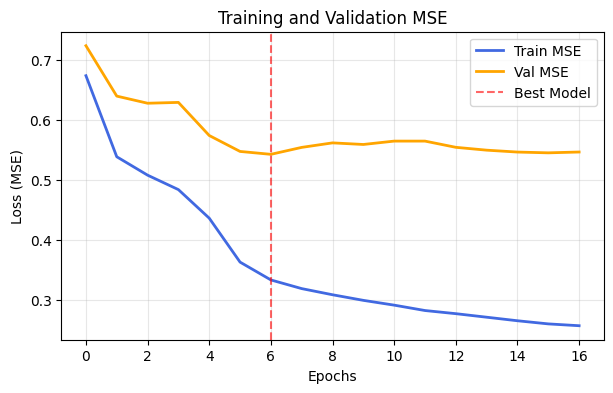

In [ ]:
import numpy as np
import os
from utils.visualization import plot_learning_curves


saved_data = np.load(os.path.join(save_artifacts_dir, "metrics.npz"))
history = {key: saved_data[key].tolist() for key in saved_data.files}

# Plot 
plot_learning_curves(
    history=history, 
    show=True,
    save_path=None, 
)

## Evaluation

### metrics saved


In [16]:
from engine.evaluator import Evaluator
import os, json, numpy as np

In [14]:
save_run_dir = "runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11"
save_artifacts_dir = "runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/train"
save_test_dir = "runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/test"

In [19]:
import torch

weights_path = os.path.join(save_artifacts_dir, "best_model.pt")
model_eval = SimpleGRUModel(configs=configs, verbose=False).to(configs.device)
model_eval.load_state_dict(torch.load(weights_path, map_location=configs.device))

print("Loaded best weights from:", weights_path)


Loaded best weights from: runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/train/best_model.pt


evaluate ALL splits into timestamp/test/

In [23]:
import numpy as np

npz_path = "runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/test/val_outputs.npz"
val_outs = np.load(npz_path)
val_outs.files

['X', 'Y', 'P']

In [ ]:
evaluator = Evaluator(device=configs.device)


# Test split
test_metrics = evaluator.evaluate(
    model=model_eval,
    loader=test_loader,
    split="test",
    save_dir=save_test_dir,
    save_npz=True,
    verbose=True,
)

[evaluator] Collected outputs: X(12003, 96, 7), Y(12003, 96, 7), P(12003, 96, 7)
[evaluator] Saved JSON -> runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/test/train_metrics.json
[evaluator] Saved NPZ  -> runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/test/train_outputs.npz
[evaluator] Collected outputs: X(2422, 96, 7), Y(2422, 96, 7), P(2422, 96, 7)
[evaluator] Saved JSON -> runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/test/test_metrics.json
[evaluator] Saved NPZ  -> runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/test/test_outputs.npz


In [ ]:
# print("train_metrics:", train_metrics)
# print("val_metrics:", val_metrics)
# print("test_metrics:", test_metrics)

train_metrics: {'mse': 0.3269994556903839, 'mae': 0.40397149324417114}
val_metrics: {'mse': 0.38027137517929077, 'mae': 0.41861534118652344}
test_metrics: {'mse': 0.4637983441352844, 'mae': 0.49551281332969666}


### plots

In [29]:
save_run_dir = "runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11"
save_artifacts_dir = "runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/train"
save_test_dir = "runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/test"

In [33]:
import os
import numpy as np


split = "test"   # "train" | "val" | "test"
npz_path = os.path.join(save_test_dir, f"{split}_outputs.npz")

print("NPZ exists:", os.path.exists(npz_path))
print("NPZ path:", npz_path)

NPZ exists: True
NPZ path: runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/test/test_outputs.npz


In [34]:
outs = np.load(npz_path)
print("keys:", outs.files)
print("X:", outs["X"].shape, "Y:", outs["Y"].shape, "P:", outs["P"].shape)


keys: ['X', 'Y', 'P']
X: (2422, 96, 7) Y: (2422, 96, 7) P: (2422, 96, 7)


In [52]:
import importlib
import utils.visualization
importlib.reload(utils.visualization)
from utils.visualization import plot_forecasts_from_npz


png_path = plot_forecasts_from_npz(
    npz_path=npz_path,
    # window_indices=(0, 50, 100, 200, 250),
    window_indices="random",
    num_random=3,
    seed=40,
    channel_idx=-1, 
    split_name="test",
    save_dir=save_test_dir,
    show=False,
    verbose=True,
)

[plot] Loaded NPZ: X(2422, 96, 7), Y(2422, 96, 7), P(2422, 96, 7)
[plot] Available windows: N=2422 | lookback L=96 | horizon T=96 | channels V=7
[plot] Using random window_indices (k=3): [1767, 1359, 51]
[plot] Saved -> runs/ETTh1/variate/gru/L96_T96/seed_42/2026-02-18_17-11/test/test_3_forecasts_ch-1.png
